In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/glass.csv')

In [3]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


## Пояснение к Данным:
    1. RI: refractive index
    2. Na: Sodium (unit measurement: weight percent in corresponding oxide, as are attributes 4-10)
    3. Mg: Magnesium
    4. Al: Aluminum
    5. Si: Silicon
    6. K: Potassium
    7. Ca: Calcium
    8. Ba: Barium
    9. Fe: Iron
    10. Type of glass: (class attribute)
        -- 1 building_windows_float_processed
        -- 2 building_windows_non_float_processed
        -- 3 vehicle_windows_float_processed
        -- 4 vehicle_windows_non_float_processed (none in this database)
        -- 5 containers
        -- 6 tableware
        -- 7 headlamps

In [5]:
df['Type'].value_counts()

Type
2    76
1    70
7    29
3    17
5    13
6     9
Name: count, dtype: int64

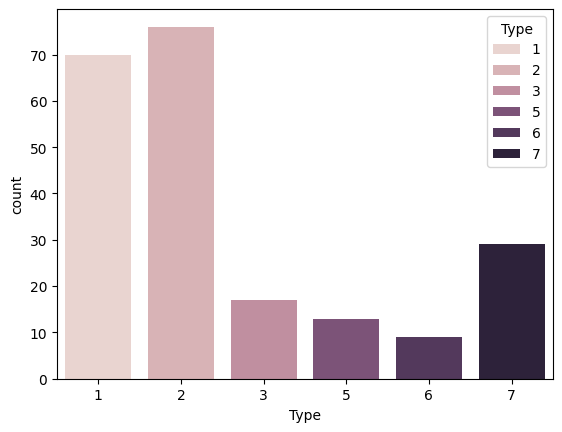

In [6]:
sns.countplot(data=df, x='Type', hue='Type');

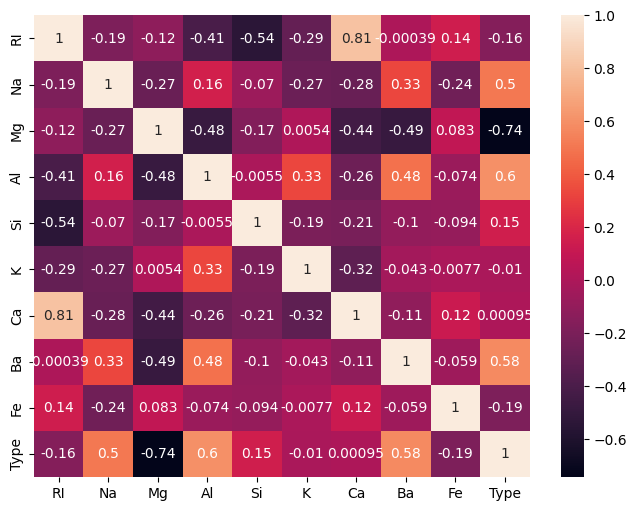

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True);

In [8]:
np.abs(df.corr()['Type']).sort_values().tail(6)

Fe      0.188278
Na      0.502898
Ba      0.575161
Al      0.598829
Mg      0.744993
Type    1.000000
Name: Type, dtype: float64

In [9]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
from sklearn.impute import KNNImputer

In [10]:
## Мы не используем Изоляционный Лес так как строк очень мало

In [11]:
X = df.drop('Type', axis=1)

In [12]:
y = df['Type']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104, stratify=y)

In [14]:
num_features = X_train.columns.tolist()

In [15]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [17]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_jobs=-1))
])

In [18]:
param_grid = {
    'model__n_neighbors': range(3, 50, 2),
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
    'model__p': [1, 1.5, 2, 3]
}

In [19]:
grid_pipe = GridSearchCV(estimator=pipe,
                         param_grid=param_grid,
                         scoring='f1_macro',
                         n_jobs=-1,
                         cv=5
)

In [20]:
%%time
grid_pipe.fit(X_train, y_train)

CPU times: total: 1.92 s
Wall time: 8.96 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(3, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [21]:
y_pred = grid_pipe.predict(X_test)
y_pred_proba = grid_pipe.predict_proba(X_test)
y_train_proba = grid_pipe.predict_proba(X_train)

In [22]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, average=None)
precision = precision_score(y_test, y_pred, average=None)

roc_auc_test = roc_auc_score(y_test, y_pred_proba, average=None, multi_class='ovr')
roc_auc_train = roc_auc_score(y_train, y_train_proba, average=None, multi_class='ovr')

In [23]:
best_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_knn.weights}")
print(f"  Формула расстояния (metric):      {best_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_knn.algorithm}")
print(f"                            P:      {best_knn.p}")

  Количество соседей (n_neighbors): 3
  Функция весов (weights):          distance
  Формула расстояния (metric):      manhattan
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [24]:
accuracy

0.7209302325581395

In [25]:
recall

array([0.92857143, 0.6       , 0.33333333, 1.        , 0.5       ,
       0.66666667])

In [26]:
precision

array([0.68421053, 0.81818182, 0.5       , 0.5       , 1.        ,
       1.        ])

In [27]:
roc_auc_test

array([0.95566502, 0.88452381, 0.625     , 0.99166667, 0.98780488,
       0.91666667])

In [28]:
roc_auc_train

array([1., 1., 1., 1., 1., 1.])

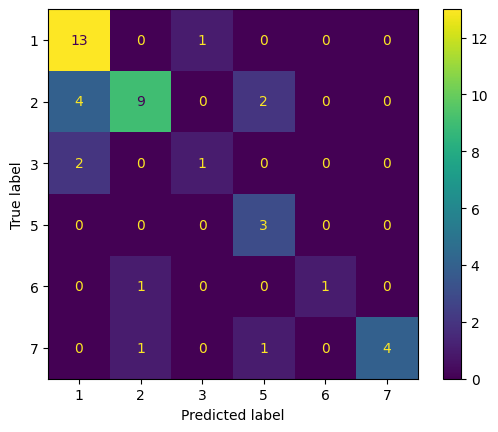

In [29]:
ConfusionMatrixDisplay.from_estimator(grid_pipe, X_test, y_test);

In [30]:
def plot_multiclass_roc(clf, X_test, y_test, n_classes, figsize=(5,5)):
    y_score = clf.predict_proba(X_test)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    y_test_dummies = pd.get_dummies(y_test, drop_first=False).values
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_dummies[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Receiver operating characteristic example')
    for i in range(n_classes):
        ax.plot(fpr[i], tpr[i], label='ROC curve (area = %0.2f) for label %i' % (roc_auc[i], i))
    ax.legend(loc="best")
    ax.grid(alpha=.4)
    sns.despine()
    plt.show()

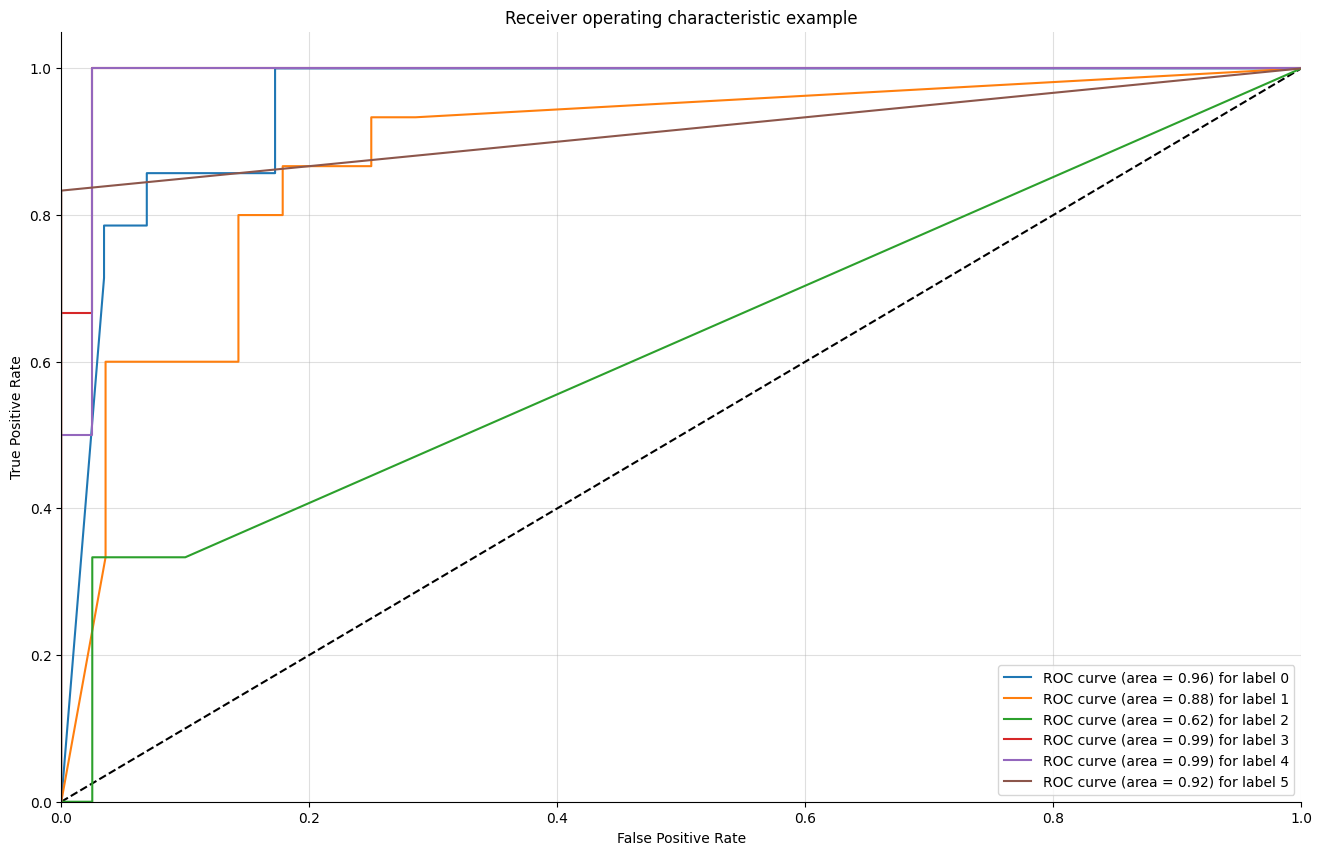

In [31]:
plot_multiclass_roc(grid_pipe, X_test, y_test, n_classes=6, figsize=(16, 10))

In [32]:
grid_pipe.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(3, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [33]:
y_full_proba = grid_pipe.predict_proba(X)

In [34]:
best_final_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_final_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_final_knn.weights}")
print(f"  Формула расстояния (metric):      {best_final_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_final_knn.algorithm}")
print(f"                            P:      {best_final_knn.p}")

  Количество соседей (n_neighbors): 3
  Функция весов (weights):          distance
  Формула расстояния (metric):      manhattan
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [35]:
roc_auc_full = roc_auc_score(y, y_full_proba, average=None, multi_class='ovr')

In [36]:
roc_auc_full

array([1., 1., 1., 1., 1., 1.])

In [37]:
df[df['Type'] == 2].head(3)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
70,1.51574,14.86,3.67,1.74,71.87,0.16,7.36,0.0,0.12,2
71,1.51848,13.64,3.87,1.27,71.96,0.54,8.32,0.0,0.32,2
72,1.51593,13.09,3.59,1.52,73.10,0.67,7.83,0.0,0.00,2


In [38]:
df[df['Type'] == 3].head(3)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
146,1.51769,13.65,3.66,1.11,72.77,0.11,8.60,0.0,0.0,3
147,1.51610,13.33,3.53,1.34,72.67,0.56,8.33,0.0,0.0,3
148,1.51670,13.24,3.57,1.38,72.70,0.56,8.44,0.0,0.1,3


In [39]:
df[df['Type'] == 5].head(3)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
163,1.51514,14.01,2.68,3.50,69.89,1.68,5.87,2.2,0.0,5
164,1.51915,12.73,1.85,1.86,72.69,0.60,10.09,0.0,0.0,5
165,1.52171,11.56,1.88,1.56,72.86,0.47,11.41,0.0,0.0,5


In [40]:
glass_custom_profiles = {
    'RI': [1.52153, 1.51524, 1.51719, 1.51464, 1.51165, 1.51753],
    'Na': [13.645, 14.855,  13.645,  14.005,  17.375,  14.115],
    'Mg': [4.485,  3.665,   3.655,   2.675,   0.005,   0.005],
    'Al': [1.105,  1.735,   1.105,   3.495,   3.495,   2.495],
    'Si': [71.775, 71.875,  72.765,  69.885,  75.405,  73.395],
    'K':  [0.055,  0.155,   0.105,   1.675,   0.005,   0.115],
    'Ca': [8.745,  7.355,   8.595,   5.865,   3.705,   8.915],
    'Ba': [0.005,  0.005,   0.005,   2.195,   0.005,   1.585],
    'Fe': [0.005,  0.115,   0.005,   0.005,   0.005,   0.005]
}

In [41]:
custom_glass_df = pd.DataFrame(glass_custom_profiles)

In [42]:
custom_glass_df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52153,13.645,4.485,1.105,71.775,0.055,8.745,0.005,0.005
1,1.51524,14.855,3.665,1.735,71.875,0.155,7.355,0.005,0.115
2,1.51719,13.645,3.655,1.105,72.765,0.105,8.595,0.005,0.005
3,1.51464,14.005,2.675,3.495,69.885,1.675,5.865,2.195,0.005
4,1.51165,17.375,0.005,3.495,75.405,0.005,3.705,0.005,0.005
5,1.51753,14.115,0.005,2.495,73.395,0.115,8.915,1.585,0.005


In [43]:
glass_preds = grid_pipe.best_estimator_.predict(custom_glass_df)
glass_probs = grid_pipe.best_estimator_.predict_proba(custom_glass_df)

In [44]:
glass_types_map = {
    1: "🪟 Строительное оконное (Float processed)",
    2: "🏠 Строительное оконное (Non-float processed)",
    3: "🚗 Автомобильное стекло (Float processed)",
    5: "🧪 Контейнеры и банки (Containers)",
    6: "🍽️ Посуда / Столовые приборы (Tableware)",
    7: "🚨 Автомобильные фары (Headlamps) 💡"
}

print("="*90)
print("🔎 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ОСКОЛКАМ СТЕКЛА:")
print("="*90)

expected_classes = [1, 2, 3, 5, 6, 7]

for idx, expected in enumerate(expected_classes):
    predicted_class = glass_preds[idx]

    class_indices = list(grid_pipe.best_estimator_.classes_)
    pred_idx_in_proba = class_indices.index(predicted_class)
    confidence = glass_probs[idx][pred_idx_in_proba] * 100
    
    print(f"Осколок №{idx+1} (Ожидался Класс {expected}):")
    print(f"  -> Вердикт модели: {glass_types_map.get(predicted_class, 'Неизвестный тип')}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 90)

🔎 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ОСКОЛКАМ СТЕКЛА:
Осколок №1 (Ожидался Класс 1):
  -> Вердикт модели: 🪟 Строительное оконное (Float processed)
  -> Уверенность модели: 100.00%
------------------------------------------------------------------------------------------
Осколок №2 (Ожидался Класс 2):
  -> Вердикт модели: 🏠 Строительное оконное (Non-float processed)
  -> Уверенность модели: 100.00%
------------------------------------------------------------------------------------------
Осколок №3 (Ожидался Класс 3):
  -> Вердикт модели: 🚗 Автомобильное стекло (Float processed)
  -> Уверенность модели: 70.12%
------------------------------------------------------------------------------------------
Осколок №4 (Ожидался Класс 5):
  -> Вердикт модели: 🧪 Контейнеры и банки (Containers)
  -> Уверенность модели: 94.68%
------------------------------------------------------------------------------------------
Осколок №5 (Ожидался Класс 6):
  -> Вердикт модели: 🍽️ Посуда / Столовые приборы (Tableware)
  ->

In [45]:
blind_test_profile = {
    'RI': [1.51514],
    'Na': [14.01],
    'Mg': [2.68],
    'Al': [3.50],
    'Si': [69.89],
    'K':  [1.68],
    'Ca': [5.87],
    'Ba': [2.20], 
    'Fe': [0.00]
}

In [46]:
blind_df = pd.DataFrame(blind_test_profile)

In [47]:
blind_df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.51514,14.01,2.68,3.5,69.89,1.68,5.87,2.2,0.0


In [48]:
blind_pred = grid_pipe.best_estimator_.predict(blind_df)[0]
blind_prob = grid_pipe.best_estimator_.predict_proba(blind_df)

In [49]:
glass_types_map = {
    1: "🪟 Строительное оконное (Float processed)",
    2: "🏠 Строительное оконное (Non-float processed)",
    3: "🚗 Автомобильное стекло (Float processed)",
    5: "🧪 Контейнеры и банки (Containers)",
    6: "🍽️ Посуда / Столовые приборы (Tableware)",
    7: "🚨 Автомобильные фары (Headlamps) 💡"
}


class_indices = list(grid_pipe.best_estimator_.classes_)
pred_idx = class_indices.index(blind_pred)
blind_confidence = blind_prob[0][pred_idx] * 100

print("="*90)
print("🔎 ОТВЕТ МОДЕЛИ:")
print("="*90)
print(f"  -> Итоговый вердикт ИИ: {glass_types_map.get(blind_pred, 'Неизвестный тип')}")
print(f"  -> Уверенность модели:   {blind_confidence:.2f}%")
print("="*90)

🔎 ОТВЕТ МОДЕЛИ:
  -> Итоговый вердикт ИИ: 🧪 Контейнеры и банки (Containers)
  -> Уверенность модели:   100.00%


In [50]:
## Модель и вправду ответила на вопрос верно так как ответ и был Контейнеры и банки

In [51]:
class_percents = df['Type'].value_counts(normalize=True) * 100

baseline_string = f"1: {class_percents[1]:.1f}%, 2: {class_percents[2]:.1f}%, 3: {class_percents[3]:.1f}%, 5: {class_percents[5]:.1f}%, 6: {class_percents[6]:.1f}%, 7: {class_percents[7]:.1f}%"
print(f"{baseline_string}")

1: 32.7%, 2: 35.5%, 3: 7.9%, 5: 6.1%, 6: 4.2%, 7: 13.6%


In [52]:
import json
import os

advanced_report = {
    "project": "Glass Type Prediction",
    "model": "KNeighborsClassifier",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_knn.n_neighbors,
        "weights": best_knn.weights,
        "metric": best_knn.metric,
        "p": best_knn.p
    },
    "final_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_final_knn.n_neighbors,
        "weights": best_final_knn.weights,
        "metric": best_final_knn.metric,
        "p": best_final_knn.p
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": {
            "building_windows_float_processed": precision[0],
            "building_windows_non_float_processed" : precision[1],
            "vehicle_windows_float_processed": precision[2],
            "containers": precision[3],
            "tableware": precision[4],
            "headlamps": precision[5]
        },
        "Recall Score": {
            "building_windows_float_processed": recall[0],
            "building_windows_non_float_processed" : recall[1],
            "vehicle_windows_float_processed": recall[2],
            "containers": recall[3],
            "tableware": recall[4],
            "headlamps": recall[5]
        },
        "ROC AUC Train Score": {
            "building_windows_float_processed": roc_auc_train[0],
            "building_windows_non_float_processed" : roc_auc_train[1],
            "vehicle_windows_float_processed": roc_auc_train[2],
            "containers": roc_auc_train[3],
            "tableware": roc_auc_train[4],
            "headlamps": roc_auc_train[5]
        },
        "ROC AUC Test Score": {
            "building_windows_float_processed": roc_auc_test[0],
            "building_windows_non_float_processed" : roc_auc_test[1],
            "vehicle_windows_float_processed": roc_auc_test[2],
            "containers": roc_auc_test[3],
            "tableware": roc_auc_test[4],
            "headlamps": roc_auc_test[5]
        },
        "ROC AUC Full Score": {
            "building_windows_float_processed": roc_auc_full[0],
            "building_windows_non_float_processed" : roc_auc_full[1],
            "vehicle_windows_float_processed": roc_auc_full[2],
            "containers": roc_auc_full[3],
            "tableware": roc_auc_full[4],
            "headlamps": roc_auc_full[5]
        },
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [53]:
from joblib import dump, load

In [54]:
dump(grid_pipe, "model/glass_type_predict_k_neighbors_classifier_2026_v1.pkl")

['model/glass_type_predict_k_neighbors_classifier_2026_v1.pkl']

In [55]:
loaded_pipe = load("model/glass_type_predict_k_neighbors_classifier_2026_v1.pkl")

In [56]:
glass_preds = loaded_pipe.best_estimator_.predict(custom_glass_df)
glass_probs = loaded_pipe.best_estimator_.predict_proba(custom_glass_df)

In [57]:
glass_types_map = {
    1: "🪟 Строительное оконное (Float processed)",
    2: "🏠 Строительное оконное (Non-float processed)",
    3: "🚗 Автомобильное стекло (Float processed)",
    5: "🧪 Контейнеры и банки (Containers)",
    6: "🍽️ Посуда / Столовые приборы (Tableware)",
    7: "🚨 Автомобильные фары (Headlamps) 💡"
}

print("="*90)
print("🔎 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ОСКОЛКАМ СТЕКЛА:")
print("="*90)

expected_classes = [1, 2, 3, 5, 6, 7]

for idx, expected in enumerate(expected_classes):
    predicted_class = glass_preds[idx]

    class_indices = list(grid_pipe.best_estimator_.classes_)
    pred_idx_in_proba = class_indices.index(predicted_class)
    confidence = glass_probs[idx][pred_idx_in_proba] * 100
    
    print(f"Осколок №{idx+1} (Ожидался Класс {expected}):")
    print(f"  -> Вердикт модели: {glass_types_map.get(predicted_class, 'Неизвестный тип')}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 90)

🔎 РЕЗУЛЬТАТЫ МОДЕЛИ ПО ОСКОЛКАМ СТЕКЛА:
Осколок №1 (Ожидался Класс 1):
  -> Вердикт модели: 🪟 Строительное оконное (Float processed)
  -> Уверенность модели: 100.00%
------------------------------------------------------------------------------------------
Осколок №2 (Ожидался Класс 2):
  -> Вердикт модели: 🏠 Строительное оконное (Non-float processed)
  -> Уверенность модели: 100.00%
------------------------------------------------------------------------------------------
Осколок №3 (Ожидался Класс 3):
  -> Вердикт модели: 🚗 Автомобильное стекло (Float processed)
  -> Уверенность модели: 70.12%
------------------------------------------------------------------------------------------
Осколок №4 (Ожидался Класс 5):
  -> Вердикт модели: 🧪 Контейнеры и банки (Containers)
  -> Уверенность модели: 94.68%
------------------------------------------------------------------------------------------
Осколок №5 (Ожидался Класс 6):
  -> Вердикт модели: 🍽️ Посуда / Столовые приборы (Tableware)
  ->